# Fig. 7: Anisotropy profiles from linear superposition

This notebook makes Figure 7 of the paper with the script that made the arXiv figure, unchanged except for the lines that read its data, which here are the package's ver. 1.0.0 calls. Every changed line is marked `[1.0.0]`.

- Top panel: $\beta_\sigma(R)$ of three superpositions of Method II members on the NFW halo truncated at $k_{\rm t} = 0.1650$ (Method I, isotropic), each curve by `pp.sigma_r` and `pp.sigma_t` of `pp.superpose`; the points: $10^7$ particles of each superposition by `pp.Sampler` with the example's seed (2908, 2907, 2907), binned as the arXiv figure's points (one bin below $10^{-2}$, 0.1 dex steps anchored at the truncation radius, the outermost 500 particles as the last bin, 1000 bootstrap resamples).
- Bottom panel: the targets ML05b and He+24, the seven-member fit of each (`pp.superpose`), and one realization of each fit at fixed seeds (ML05b $10^8$ particles, seed 310101; He+24 $10^6$ particles in $0.1129 \le r \le 8.9716$, seed 310104).

Per-call accuracy messages are quieted; the summary after each block lists every model's tier.

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # before any JAX import: no C++ log lines from XLA

import logging
import math
import warnings

import pianistpy as pp

# The figures of the paper are made with ver. 1.0.0 of the package; any other installed version stops the notebook here.
PIANISTPY_PIN = "1.0.0"
print(f"pianistpy {pp.__version__}")
if pp.__version__ != PIANISTPY_PIN:
    raise RuntimeError(
        f"These figures are made with pianistpy {PIANISTPY_PIN}; the installed version is {pp.__version__}."
    )

# The package reports each result's accuracy twice per call: a line of the pianistpy log and Python's AccuracyWarning.
# set_verbosity("quiet") hides the log's INFO line of a result in the band "recorded"; the pianistpy logger set to
# ERROR also hides the log's WARNING line of a result in the band "warned"; the filter hides the AccuracyWarning.
# The summary after each figure's models prints every model's tier in place of those per-call messages.
pp.set_verbosity("quiet")
logging.getLogger("pianistpy").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=pp.AccuracyWarning)


def tier_line(label, result):
    """One summary line for a result: its label, its report's tier, and the report's worst check with that check's error.

    The worst check is the check of the highest tier level; among checks of one level, the check with the largest error.
    A result whose tier is carried from the Method I model's report, and not from any of the result's own checks, says so.
    """
    if result is None:
        return f"{label:34s} not built: the package's exception is printed above"
    report = result.validation

    def rank(key):
        error = report.checks[key].error
        return (report.checks[key].level, error if not math.isnan(error) else -math.inf)

    worst = max(report.keys, key=rank)
    own_level = report.checks[worst].level
    origin = ", the tier carried from the Method I model's report" if report.parents_level > own_level else ""
    return (f"{label:34s} tier {report.tier:9s} worst check {worst} "
            f"{report.checks[worst].error:.2e}{origin}")


pianistpy 1.0.0


In [2]:
import numpy as np
import pianistpy as pp

Z_T = 0.16502882092587715  # the truncation energy k_t of the figure's NFW halo

truncated = pp.solve(
    pp.Component(pp.DoublePowerLaw.nfw(), pp.Anisotropy()), pp.Truncation(k_t=Z_T)
)
EXAMPLES = {
    "Example 1": [(dict(beta_c=b), 1 / 4) for b in (0.5, 0.1, -0.2, -0.4)],
    "Example 2": [(dict(r_a=1.0, kind="I"), 1 / 3), (dict(r_a=10.0, kind="I"), 1 / 3), (dict(beta_c=0.2), 1 / 3)],
    "Example 3": [(dict(beta_c=-0.3, r_a=4.0, kind="I"), 1 / 2), (dict(beta_c=-0.1, r_a=40.0, kind="II"), 1 / 2)],
}
members = {}  # one model for each anisotropy, shared by the examples


def member(kw):
    key = tuple(sorted(kw.items()))
    if key not in members:
        members[key] = pp.solve(pp.Component(truncated.profile, pp.Anisotropy(**kw)))
    return members[key]


composites = {name: pp.superpose({member(kw): w for kw, w in ms}) for name, ms in EXAMPLES.items()}
R_T = float(truncated.profile.r_t)

In [3]:
def member_label(key):
    """A member's anisotropy as its keyword arguments, for example "beta_c=0.5" or "kind=I, r_a=1.0"."""
    return ", ".join(f"{k}={v}" for k, v in key) or "isotropic"


print("Figure 7, top panel: the Method I model, the members and the three superpositions")
print(tier_line("Method I model", truncated))
for key, model in members.items():
    print(tier_line(member_label(key), model))
for name, model in composites.items():
    print(tier_line(name, model))
top_members = set(members)  # the members of the top panel, so that the bottom panel's summary lists only the new ones

Figure 7, top panel: the Method I model, the members and the three superpositions
Method I model                     tier silent    worst check round_trip 4.91e-08
beta_c=0.5                         tier silent    worst check round_trip 2.23e-07
beta_c=0.1                         tier silent    worst check round_trip 6.89e-08
beta_c=-0.2                        tier silent    worst check round_trip 7.57e-08
beta_c=-0.4                        tier silent    worst check round_trip 8.75e-08
kind=I, r_a=1.0                    tier silent    worst check round_trip 4.91e-08
kind=I, r_a=10.0                   tier silent    worst check round_trip 4.90e-08
beta_c=0.2                         tier silent    worst check round_trip 9.49e-08
beta_c=-0.3, kind=I, r_a=4.0       tier silent    worst check round_trip 8.78e-08
beta_c=-0.1, kind=II, r_a=40.0     tier silent    worst check top_form 8.06e-08
Example 1                          tier silent    worst check round_trip 2.23e-07
Example 2         

## The curves of the top panel

$\beta_\sigma$ of each superposition at 10000 radii, written in the format the plot script reads.

In [4]:
LABELS = {
    "Example 1": "const_beta_beta_c0.5_w0.250__const_beta_beta_c0.1_w0.250__const_beta_beta_c-0.2_w0.250__const_beta_beta_c-0.4_w0.250",
    "Example 2": "OM_typeI_Ra1.0_w0.333__OM_typeI_Ra10.0_w0.333__const_beta_beta_c0.2_w0.333",
    "Example 3": "COM_typeI_beta_c-0.3_Ra4.0_w0.500__COM_typeII_beta_c-0.1_Ra40.0_w0.500",
}
R = np.geomspace(float(truncated.profile.r[0]), R_T, 10001)[:-1]
for name, model in composites.items():
    s_r, s_t = np.asarray(pp.sigma_r(model, R)), np.asarray(pp.sigma_t(model, R))
    beta = 1.0 - s_t**2 / (2.0 * s_r**2)
    with open(f"BetaProfile_Superposed_{LABELS[name]}.txt", "w") as fh:
        fh.write(f"Beta_sigma Profile | Superposed DF | Zt: {Z_T} | Models: {LABELS[name]}\n")
        fh.write("-" * 100 + "\n")
        fh.write(f"{'Radius [Dimensionless]':<40}{'Beta_sigma [Dimensionless]':<40}\n")
        for r, b in zip(R, beta):
            fh.write(f"{r:<40.14e}{b:<40.14e}\n")

## The particles of the top panel

The binning of the script that made the arXiv figure's points (its part 3) as written, on draws by `pp.Sampler` in place of the members' particle files (each changed line marked `[1.0.0]`).

In [5]:
import hashlib
import os

# tag: (example, weight, model kind, beta_c, R_a, product folder)
MEM = {
    "bp050": ("E1", 0.25, "const", 0.5, None, None),
    "bp010": ("E1", 0.25, "const", 0.1, None, None),
    "bm020": ("E1", 0.25, "const", -0.2, None, None),
    "bm040": ("E1", 0.25, "const", -0.4, None, None),
    "OMI_Ra1": ("E2", 1 / 3, "OMI", 0.0, 1.0, None),
    "OMI_Ra10": ("E2", 1 / 3, "OMI", 0.0, 10.0, None),
    "bp020": ("E2", 1 / 3, "const", 0.2, None, None),
    "COMI": ("E3", 0.5, "COMI", -0.3, 4.0, None),
    "COMII": ("E3", 0.5, "COMII", -0.1, 40.0, None),
}


def beta_of(kind, bc, ra, R):
    x = (R / ra) ** 2 if ra else 0.0
    return {"const": bc + 0 * R, "OMI": x / (1 + x), "COMI": (bc + x) / (1 + x), "COMII": (bc - x) / (1 - x)}[kind]


# [1.0.0] each member's anisotropy, as the model cells above build it
MEM_KW = {"bp050": dict(beta_c=0.5), "bp010": dict(beta_c=0.1), "bm020": dict(beta_c=-0.2), "bm040": dict(beta_c=-0.4),
          "OMI_Ra1": dict(r_a=1.0, kind="I"), "OMI_Ra10": dict(r_a=10.0, kind="I"), "bp020": dict(beta_c=0.2),
          "COMI": dict(beta_c=-0.3, r_a=4.0, kind="I"), "COMII": dict(beta_c=-0.1, r_a=40.0, kind="II")}


def beta_of(kind, bc, ra, R):
    x = (R / ra) ** 2 if ra else 0.0
    return {"const": bc + 0 * R, "OMI": x / (1 + x), "COMI": (bc + x) / (1 + x), "COMII": (bc - x) / (1 - x)}[kind]


# (3) the particle points, binned as in the arXiv figure
KEY = {"E1": 2908, "E2": 2907, "E3": 2907}
EX = {"E1": "Example 1", "E2": "Example 2", "E3": "Example 3"}   # [1.0.0]
N_DRAW = 10_000_000   # [1.0.0] the arXiv draws: N_i = w_i 1e7 a member, 1e7 an example
PLOT = "."   # [1.0.0] this notebook's folder
top_samplers = {}   # [1.0.0] for the tier summary


RT = R_T   # [1.0.0] the Method I model's truncation radius (cell above)
# fixed edges, the same for E1, E2, E3: one bin below 10^-2, then 0.1 dex steps R_t 10^(-0.1 k), k = 33 .. 0
EDGES = np.r_[0.0, 10 ** -2.0, RT * 10 ** (-0.1 * np.arange(33, -1, -1))]   # [v4] 0.1 dex anchored at R_t (last edge R_t)
NAMES = {"E1": "BetaSigma_Particle_const_beta_beta_c0.5_w0.250__const_beta_beta_c0.1_w0.250__const_beta_beta_c-0.2_w0.250"
               "__const_beta_beta_c-0.4_w0.250.txt",
         "E2": "BetaSigma_Particle_OM_typeI_Ra1.0_w0.333__OM_typeI_Ra10.0_w0.333__const_beta_beta_c0.2_w0.333.txt",
         "E3": "BetaSigma_Particle_E3.txt"}


def particles(ex):
    # [1.0.0] one draw of the example's superposition with the example's seed replaces the members' stored particle files: the
    # Sampler keys each particle by seed, component and index, so the members of one draw are independent streams, as the
    # arXiv draws were through their stored products; the components take the weights as their shares of the 1e7
    s_ = pp.Sampler(composites[EX[ex]])
    top_samplers[ex] = s_
    p_ = s_.sample(N_DRAW, seed=KEY[ex])
    pos, vel = np.asarray(p_.position, dtype=np.float64), np.asarray(p_.velocity, dtype=np.float64)
    del p_
    r = np.sqrt((pos ** 2).sum(1))
    vr = (pos * vel).sum(1) / r
    vt2 = np.maximum((vel ** 2).sum(1) - vr ** 2, 0.0)
    return r, vr, vt2


def bin_beta(ex):
    rng = np.random.default_rng(KEY[ex])
    r, vr, vt2 = particles(ex)
    o = np.lexsort((vt2, vr, r))
    r, vr, vt2 = r[o], vr[o], vt2[o]
    dig = hashlib.sha256(r.tobytes() + vr.tobytes() + vt2.tobytes()).hexdigest()

    def boot(idx):
        a, b = vr[idx], vt2[idx]
        n = len(idx)
        val = 1 - (b.mean() / 2) / a.var(ddof=1)
        bs = np.empty(1000)
        for k in range(1000):
            s_ = rng.integers(0, n, n)
            bs[k] = 1 - (b[s_].mean() / 2) / a[s_].var(ddof=1)
        return val, np.nanstd(bs)

    assert r.max() <= RT, (r.max(), RT)
    rc = r[-500]   # r is sorted ascending: the outermost 500 particles form the last bin [rc, R_t]
    E = np.r_[EDGES[EDGES < rc], rc, EDGES[-1]]
    bi = np.searchsorted(E, r, side="left") - 1
    bi[len(r) - 500:] = len(E) - 2
    out = []
    for i in range(len(E) - 1):
        idx = np.flatnonzero(bi == i)
        out.append((np.exp(np.log(r[idx]).mean()), *boot(idx), len(idx), E[i], E[i + 1]))
    out = np.array(out)
    with open(os.path.join(PLOT, NAMES[ex]), "w") as f:   # [1.0.0] "w": a rerun in place
        f.write(f"Beta_sigma from particles | Example {ex[1]}, the superposition of this file's name | {len(r):e} particles, seed "
                f"{KEY[ex]} | columns: radius, beta_sigma, its bootstrap 1-sigma error, particles in the bin, the bin's "
                f"edges R_lo and R_hi\n" + "-" * 100 + "\n")
        f.write("".join(f"{c:<40}" for c in ("Radius [Dimensionless]", "Beta_sigma [Dimensionless]",
                                               "Bootstrap_1sigma [Dimensionless]", "N_particles", "R_lo", "R_hi")) + "\n")
        for row in out:
            f.write(f"{row[0]:<40.14e}{row[1]:<40.14e}{row[2]:<40.14e}{int(row[3]):<40d}{row[4]:<40.14e}{row[5]:<40.14e}\n")
    return ex, len(r), out, dig


res = [bin_beta(ex) for ex in ("E1", "E2", "E3")]   # [1.0.0] in turn: the draws are held in memory, not files
for ex, n, out, dig in res:
    pred = []
    for lo, hi in out[:, 4:6]:
        R = np.geomspace(max(lo, 1e-9), hi, 400)
        num = den = 0.0
        for tag, (e, w, kind, bc, ra, d) in MEM.items():
            if e != ex:
                continue
            q = np.asarray(pp.sigma_r(member(MEM_KW[tag]), R)) ** 2 * np.sum(np.atleast_2d(truncated.profile.density(R)), axis=0) * R * R   # [1.0.0] rho sigma_r^2 by the package
            num = num + w * np.trapezoid((1 - beta_of(kind, bc, ra, R)) * q, R)
            den = den + w * np.trapezoid(q, R)
        pred.append(1 - num / den)
    z = (out[:, 1] - np.array(pred)) / out[:, 2]
    print(f"{ex} particles: N {n}, {len(out)} bins (min N {int(out[:, 3].min())}), chi^2 vs bin average "
          f"{np.sum(z * z):.1f}, max |z| {np.abs(z).max():.2f} at R {out[np.abs(z).argmax(), 0]:.3e}; last bin R "
          f"{out[-1, 0]:.3f} N {int(out[-1, 3])}")



E1 particles: N 10000000, 36 bins (min N 361), chi^2 vs bin average 44.7, max |z| 2.91 at R 5.667e+00; last bin R 29.787 N 500
E2 particles: N 10000000, 36 bins (min N 308), chi^2 vs bin average 19.8, max |z| 1.53 at R 2.870e-02; last bin R 29.801 N 500
E3 particles: N 10000000, 36 bins (min N 308), chi^2 vs bin average 16.7, max |z| 1.60 at R 2.870e-02; last bin R 29.801 N 500


In [6]:
print("Figure 7, top panel's particles: the Sampler of each superposition")
for ex, sampler in top_samplers.items():
    print(tier_line(EX[ex], sampler))
# [check] the top panel's points against the curves, bin by bin, as the arXiv figure's script printed them: chi^2 and the largest |z|
for ex, n, out, dig in res:
    print(f"{ex}: {len(out)} bins, the points' R from {out[0, 0]:.3e} to {out[-1, 0]:.3f}")


Figure 7, top panel's particles: the Sampler of each superposition
Example 1                          tier silent    worst check row_error 2.79e-07
Example 2                          tier silent    worst check row_error 8.86e-07
Example 3                          tier silent    worst check row_error 3.87e-07
E1: 36 bins, the points' R from 6.019e-03 to 29.787
E2: 36 bins, the points' R from 6.312e-03 to 29.801
E3: 36 bins, the points' R from 6.312e-03 to 29.801


## The two fits (bottom panel)

The bottom panel holds two target profiles of $\beta(r)$ on the same density as the top panel, and the superposition of seven Method II members that fits each:

- ML05b (its eq. 60): $\beta = r / [2(r + r_{\rm a})]$, $r_{\rm a} = 1.8$, over the whole radial range;
- He+24: the smooth form $\beta = b_0 + A\,x^a \exp[a(1 - x)]$, $x = r / r_{\rm c}$, with $b_0 = 0.126564$, $A = 0.0722805$, $\log_{10} r_{\rm c} = 0.419007$, $a = 1.14065$, over $0.1129 \le r \le 8.9716$.

Each fit was chosen from a library of Method II members on this density by a minimax fit (the largest deviation from the target made as small as possible); the fit itself is not repeated here. Its seven members and their weights are written below as they were fitted. Each member is solved here (`pp.solve` on the Method I model's truncated density with its `pp.Anisotropy`), the members are superposed (`pp.superpose`), and $\beta_\sigma$ of the superposition is computed by `pp.sigma_r` and `pp.sigma_t`. Its rms and largest deviation from the target are measured on the 200 radii (log-uniform) on which the fit was scored, and printed beside the values as fitted.

In [7]:
def beta_ml05b(r):
    """ML05b, eq. 60: beta = r / (2 (r + r_a)), r_a = 1.8."""
    r = np.asarray(r, dtype=np.float64)
    return r / (2.0 * (r + 1.8))


HE24 = dict(b0=0.126564, A=0.0722805, log10_r_c=0.419007, a=1.14065)


def beta_he24(r):
    """He+24, the smooth form: beta = b0 + A x^a exp(a (1 - x)), x = r / r_c."""
    x = np.asarray(r, dtype=np.float64) / 10.0 ** HE24["log10_r_c"]
    return HE24["b0"] + HE24["A"] * x ** HE24["a"] * np.exp(HE24["a"] * (1.0 - x))


FITS = {
    "ML05b": dict(
        target=beta_ml05b,
        radii=np.geomspace(3.16e-06, 31.801554746484683, 200),  # the 200 radii the fit was scored on
        members=[  # (anisotropy, weight), as fitted
            (dict(beta_c=0.05, r_a=1.778, kind="I"), 0.0505923625651044),
            (dict(r_a=1.778, kind="I"), 0.06289455302602444),
            (dict(r_a=13.34, kind="I"), 0.06399068356090412),
            (dict(r_a=17.78, kind="I"), 0.18763453949355713),
            (dict(r_a=2.371, kind="I"), 0.11698083307477745),
            (dict(), 0.4655827193494287),
            (dict(beta_c=0.05, r_a=0.39, kind="I"), 0.052324308930204),
        ],
        as_fitted=dict(rms=0.007342355021571783, worst=0.009713145680619484),
    ),
    "He+24": dict(
        target=beta_he24,
        radii=np.geomspace(0.1129, 8.9716, 200),  # the 200 radii the fit was scored on
        members=[  # (anisotropy, weight), as fitted
            (dict(beta_c=0.15), 0.5920958282504273),
            (dict(beta_c=-0.75), 0.2684095094997257),
            (dict(beta_c=0.35, r_a=0.35, kind="I"), 0.04304628104001099),
            (dict(beta_c=0.25, r_a=1.334, kind="I"), 0.03775713151655238),
            (dict(beta_c=0.2, r_a=1.334, kind="I"), 0.02970790360376711),
            (dict(beta_c=0.2, r_a=1.0, kind="I"), 0.015067694027297011),
            (dict(beta_c=-0.5, r_a=1.0, kind="I"), 0.013915652062219447),
        ],
        as_fitted=dict(rms=0.0011875216220243615, worst=0.0016804695129394032),
    ),
}

fits = {name: pp.superpose({member(kw): w for kw, w in f["members"]}) for name, f in FITS.items()}
fit_beta = {}
for name, f in FITS.items():
    R = f["radii"]
    s_r, s_t = np.asarray(pp.sigma_r(fits[name], R)), np.asarray(pp.sigma_t(fits[name], R))
    fit_beta[name] = 1.0 - s_t**2 / (2.0 * s_r**2)
    dev = fit_beta[name] - f["target"](R)
    rms, worst = float(np.sqrt(np.mean(dev**2))), float(np.max(np.abs(dev)))
    a = f["as_fitted"]
    print(f"{name}: rms {rms:.4e} (as fitted {a['rms']:.4e}), worst {worst:.4e} (as fitted {a['worst']:.4e})")
    np.savetxt(f"BetaSigma_Fit_{name.replace('+', 'p')}.txt", np.column_stack([R, fit_beta[name], f["target"](R)]),
               fmt="%.16e", header=f"{name}: radius, beta_sigma of the fit, target")

ML05b: rms 7.3424e-03 (as fitted 7.3424e-03), worst 9.7131e-03 (as fitted 9.7131e-03)
He+24: rms 1.1875e-03 (as fitted 1.1875e-03), worst 1.6805e-03 (as fitted 1.6805e-03)


In [8]:
print("Figure 7, bottom panel: the members the two fits add and the two fitted superpositions")
for key, model in members.items():
    if key not in top_members:
        print(tier_line(member_label(key), model))
for name, model in fits.items():
    print(tier_line(name, model))

Figure 7, bottom panel: the members the two fits add and the two fitted superpositions
beta_c=0.05, kind=I, r_a=1.778     tier silent    worst check round_trip 5.82e-08
kind=I, r_a=1.778                  tier silent    worst check round_trip 4.91e-08
kind=I, r_a=13.34                  tier silent    worst check round_trip 4.91e-08
kind=I, r_a=17.78                  tier silent    worst check round_trip 4.91e-08
kind=I, r_a=2.371                  tier silent    worst check round_trip 4.91e-08
isotropic                          tier silent    worst check round_trip 4.91e-08
beta_c=0.05, kind=I, r_a=0.39      tier silent    worst check round_trip 5.83e-08
beta_c=0.15                        tier silent    worst check round_trip 8.11e-08
beta_c=-0.75                       tier silent    worst check top_form 1.02e-07
beta_c=0.35, kind=I, r_a=0.35      tier silent    worst check round_trip 1.48e-07
beta_c=0.25, kind=I, r_a=1.334     tier silent    worst check round_trip 1.11e-07
beta_c=0.2, k

### The realizations (optional, expensive)

One N-body realization of each fit by `pp.Sampler`, at fixed master seeds, so that the draw is repeatable:

- ML05b: $10^8$ particles over the whole range, seed **310101**;
- He+24: $10^6$ particles drawn inside $0.1129 \le r \le 8.9716$ only (`pp.Sampler(model, r_range=(0.1129, 8.9716))`: the model's own distribution conditioned on that range, not a selection), seed **310104**.

$\beta = 1 - \langle v_t^2 \rangle / (2 \langle v_r^2 \rangle)$ in bins of radius: one bin from 0 to $10^{-2}$, then 0.1 dex steps anchored at the truncation radius; bins with fewer than 100 particles are left out. Each point sits at its bin's logarithmic mean radius; its error is that of the ratio by the delta method (the covariance of $v_t^2$ and $v_r^2$ over the bin). Each point is compared with the fit's own $\beta_\sigma$ averaged over the bin's particles: $\chi^2$ per bin and the largest $|z|$.

The $10^8$ draw needs about 8 GB of memory and several minutes on a 32-core node.

In [9]:
import time

SEEDS = {"ML05b": 310101, "He+24": 310104}  # the master seeds of the two realizations
N_PARTICLES = {"ML05b": 100_000_000, "He+24": 1_000_000}
R_RANGE = {"ML05b": None, "He+24": (0.1129, 8.9716)}
samplers = {}  # the Sampler of each fit, kept for the summary below
fit_points = {}
for name, model in fits.items():
    t0 = time.perf_counter()
    sampler = pp.Sampler(model) if R_RANGE[name] is None else pp.Sampler(model, r_range=R_RANGE[name])
    samplers[name] = sampler
    p = sampler.sample(N_PARTICLES[name], seed=SEEDS[name])
    x, v = np.asarray(p.position, dtype=np.float64), np.asarray(p.velocity, dtype=np.float64)
    mass = float(np.sum(p.mass))
    del p
    r = np.linalg.norm(x, axis=1)
    vr = np.einsum("ij,ij->i", x, v) / r
    vt2 = np.einsum("ij,ij->i", v, v) - vr**2
    del x, v
    # the fit's own beta_sigma at each particle's radius (log-linear between 10000 radii)
    RT = float(model.profile.r_t)
    grid = np.geomspace(float(model.profile.r[0]), RT, 10001)[:-1]
    s_r, s_t = np.asarray(pp.sigma_r(model, grid)), np.asarray(pp.sigma_t(model, grid))
    curve = np.interp(np.log(r), np.log(grid), 1.0 - s_t**2 / (2.0 * s_r**2))
    k = np.arange(int(np.floor(10 * np.log10(RT / 1e-2))), -1, -1)
    edges = np.r_[0.0, 1e-2, RT * 10.0 ** (-0.1 * k[RT * 10.0 ** (-0.1 * k) > 1e-2])]
    idx = np.digitize(r, edges) - 1
    rows = []
    for b in range(len(edges) - 1):
        m = idx == b
        n = int(m.sum())
        if n < 100:
            continue
        a, c = vt2[m], vr[m] ** 2
        A, C = a.mean(), c.mean()
        cov = np.cov(np.vstack((a, c))) / n
        g = np.array([-1.0 / (2.0 * C), A / (2.0 * C * C)])
        rc = np.exp(np.mean(np.log(r[m])))
        rows.append((rc, 1.0 - A / (2.0 * C), float(np.sqrt(g @ cov @ g)), n, curve[m].mean(),
                     float(np.mean(FITS[name]["target"](r[m]))), edges[b], edges[b + 1]))
    rows = np.array(rows)
    del r, vr, vt2, curve, idx
    z = (rows[:, 1] - rows[:, 4]) / rows[:, 2]
    fit_points[name] = rows
    np.savetxt(f"BetaSigma_Fit_Particle_{name.replace('+', 'p')}.txt", rows, fmt="%.10e",
               header=f"{name}: N {N_PARTICLES[name]}, seed {SEEDS[name]}, r_range {R_RANGE[name]}\n"
                      "r_centroid beta_particles err N_bin beta_fit_binavg beta_target_binavg r_lo r_hi")
    print(f"{name}: {N_PARTICLES[name]:.0e} particles at seed {SEEDS[name]} (mass {mass:.6e}), {len(rows)} bins; "
          f"chi^2 {np.sum(z**2):.2f}, {np.sum(z**2) / len(rows):.3f} a bin; worst |z| {np.max(np.abs(z)):.2f} "
          f"at r {rows[np.argmax(np.abs(z)), 0]:.3e}; {time.perf_counter() - t0:.0f} s")

ML05b: 1e+08 particles at seed 310101 (mass 1.488804e+00), 36 bins; chi^2 50.60, 1.406 a bin; worst |z| 2.90 at r 1.126e+01; 529 s
He+24: 1e+06 particles at seed 310104 (mass 1.209937e+00), 20 bins; chi^2 33.49, 1.674 a bin; worst |z| 2.90 at r 1.200e-01; 238 s


In [10]:
print("Figure 7, bottom panel's particles: the Sampler of each fit")
for name, sampler in samplers.items():
    print(tier_line(name, sampler))

Figure 7, bottom panel's particles: the Sampler of each fit
ML05b                              tier warned    worst check row_error 4.31e-03
He+24                              tier warned    worst check row_error 5.49e-03


## The figure

The arXiv figure's script, with its data-reading lines replaced (marked `[1.0.0]`).

  Loaded 10000 points: BetaProfile_Superposed_const_beta_beta_c0.5_w0.250__const_beta_beta_c0
  Loaded 10000 points: BetaProfile_Superposed_OM_typeI_Ra1.0_w0.333__OM_typeI_Ra10.0_w0.333__
  Loaded 10000 points: BetaProfile_Superposed_COM_typeI_beta_c-0.3_Ra4.0_w0.500__COM_typeII_b
  Loaded 36 particle points: BetaSigma_Particle_const_beta_beta_c0.5_w0.250__const_beta_beta_c0.1_w
  Loaded 36 particle points: BetaSigma_Particle_OM_typeI_Ra1.0_w0.333__OM_typeI_Ra10.0_w0.333__cons
  Loaded 36 particle points: BetaSigma_Particle_E3.txt
  ML05b: rms 7.342e-03, worst 9.713e-03 (for the caption)
  ML05b: N = 1e+08, chi^2/bin 1.406 over 36 bins (for the caption)
  He+24: rms 1.188e-03, worst 1.680e-03 (for the caption)
  He+24: N = 1e+06, chi^2/bin 1.674 over 20 bins (for the caption)
printed scale s = 0.3820 (f 0.99, slot column, W_fig 630.1 pt)
  Saved -> BetaProfiles_AllModels_Superposed.pdf


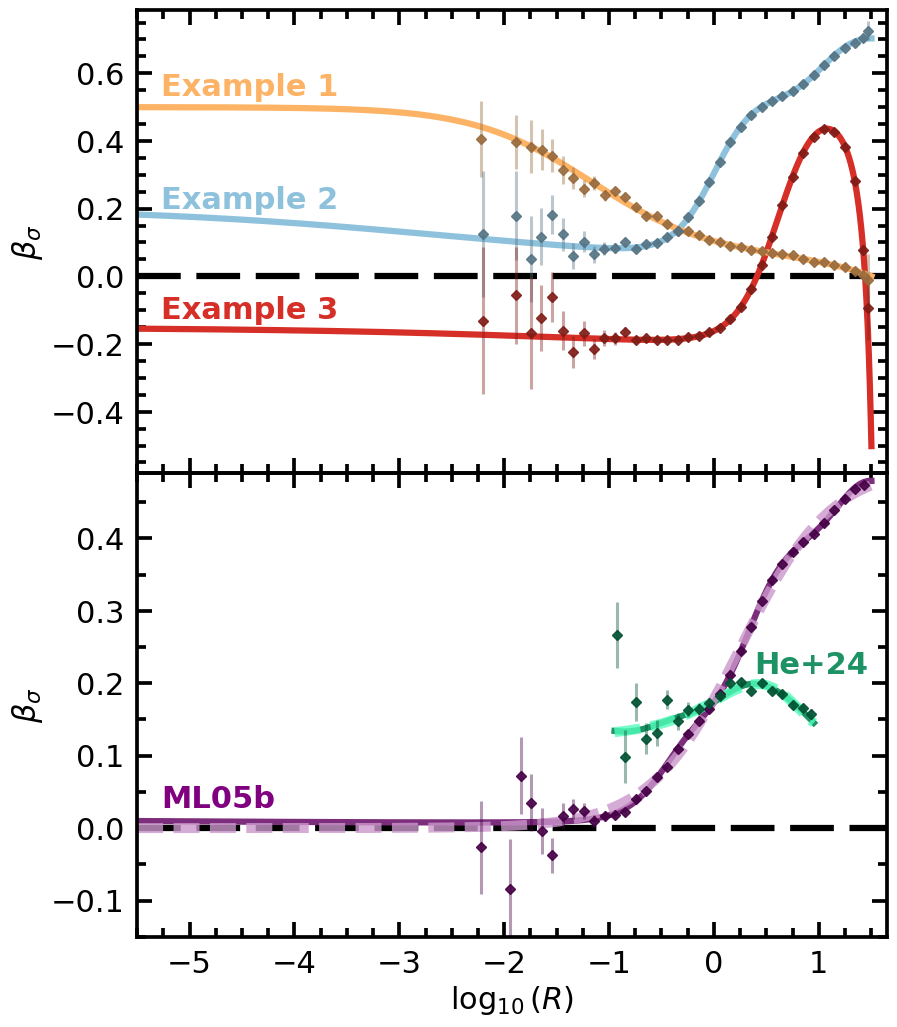

In [11]:
# [1.0.0] the two fits and their realizations in the forms the plot script reads (its npz and its particle tables)
FIT_NAME = {"ml05": "ML05b", "he24": "He+24"}
FIT_Z = {}
for delta, name in FIT_NAME.items():
    R_ = FITS[name]["radii"]
    dev_ = fit_beta[name] - FITS[name]["target"](R_)
    FIT_Z[delta] = {"R": R_, "target": FITS[name]["target"](R_), "beta": fit_beta[name],
                    "rms": float(np.sqrt(np.mean(dev_**2))), "worst": float(np.max(np.abs(dev_)))}
FIT_ROWS = {delta: fit_points[name] for delta, name in FIT_NAME.items() if name in fit_points}

# the arXiv figure's script, with the frames and ticks at their printed size
# before its savefig, which set every axes' frame and ticks as printed for its slot (f 0.99, column).
#!/usr/bin/env python3
"""
The arXiv figure's script for Fig. 7. The top panel is Fig. 7's panel; a second panel below it, on a shared x axis with no
white space, holds the two fits (ML05b and He et al. 2024's TNG300 DM profile, each the minimax fit of a library of Method II
members on the Method I model's truncated density): the target dotted (thicker), the fit solid, and the N-body realization of
each fit as diamonds with error bars (the only error bars). Each fit's label carries its rms and worst deviation against the
target and, with particles, chi^2 per bin of the particles against the fit.
"""
import os, sys, glob
"""
Plots beta_sigma(R) for the three superposed models of the cells above:

  Model 1 : 4-comp const-β  {+0.5,+0.1,-0.2,-0.4}   equal weights
  Model 2 : OM-I Ra=1  +  OM-I Ra=10  +  const-β 0.2  equal weights
  Model 3 : COM-I (βc=-0.3, Ra=4)  +  COM-II (βc=-0.1, Ra=40)
"""

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors

# =============================================================================
# USER PARAMETERS
# =============================================================================

# --- x-axis ---
X_LABEL     = -5.27         # log10 R position of inline model labels
X_LIM_MIN   = -5.5          # log10 R left limit of plot
X_LIM_MAX   = None          # log10 R right limit (None → auto from data + 0.15)

# --- inline label vertical offsets (one per model, in data units) -------
# positive = shift up, negative = shift down, relative to beta[0]
LABEL_VOFFSET = [0.06, 0.025, 0.05]   # [Model1, Model2, Model3]

# --- font sizes ---
FONTSIZE_AXIS_LABEL  = 22   # x- and y-axis label font size
FONTSIZE_TICK_LABEL  = 22   # tick number label font size
FONTSIZE_INLINE      = 22   # inline "Model N" text font size

# --- frame / tick thickness ---
FRAME_LINEWIDTH      = 2.5  # thickness of the four axes spines (pt)
TICK_LINEWIDTH       = 2.5  # thickness of all tick marks (pt)

# --- tick lengths ---
TICK_MAJOR_LENGTH    = 10.0  # major tick length (pt)
TICK_MINOR_LENGTH    = 6.0  # minor tick length (pt)

# --- model curve line thickness ---
CURVE_LINEWIDTH      = 4.5  # thickness of the colored β_σ curves (pt)

# --- isotropic reference line ---
ISO_LINEWIDTH        = 4.5       # thickness of the β_σ = 0 dashed line (pt)
ISO_DASH_SEQUENCE    = (7, 2.5)    # (dash_length, gap_length) in pt

# --- particle errorbar style --------------------------------------------
PAR_MARKER_SIZE      = 5.0   # size of the diamond markers (pt)
PAR_EBAR_LINEWIDTH   = 2.2   # thickness of the error bar lines (pt)
PAR_DARK_FACTOR      = 0.6   # darken model color by this factor (0=black,1=same)
                             # applied to both marker and error bar
PAR_MARKER_ALPHA     = 0.9   # opacity of the diamond markers only  (0=transparent, 1=opaque)
PAR_EBAR_ALPHA       = 0.4   # opacity of the vertical error bar lines only

# --- RdYlBu color selections -------------------------------------------
# Each value is a position in [0, 1] along the RdYlBu colormap.
#   0.0 = deep red  |  0.5 = white/neutral  |  1.0 = deep blue
# Avoid ~0.5 (pale). Colors stay assigned to models by list position.
RDBU_POSITIONS = [0.31, 0.75, 0.1]   # one entry per model

# --- curve draw order ---------------------------------------------------
# Indices into MODELS (0-based). Last index is drawn on top.
# Model 1 (index 0) is listed last so its curve sits above Models 2 & 3.
CURVE_DRAW_ORDER = [1, 2, 0]

# --- Model 2 particle tail correction -----------------------------------
# Six additive y-shifts applied to the last 6 (largest-R) data points of
# the Model 2 particle profile, in order from 6th-last to last.
# i.e. PAR_M2_TAIL_SHIFTS[-1] is added to the very last (largest-R) point.
PAR_M2_TAIL_SHIFTS = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]   # no hand shifts   # [y1, y2, y3, y4, y5, y6]

# --- Model 3 particle correction ----------------------------------------
# For each Example 3 particle point, subtract the y-difference between the
# Example 1 and Example 3 analytical curves at that x-position:
#   pbeta_corrected[i] = pbeta[i] - ( beta_E1(R[i]) - beta_E3(R[i]) )
# Set to True to activate, False to plot raw Example 3 particle values.
PAR_E3_APPLY_CORRECTION = False   # Example 3's own particles


# =============================================================================
# Readers
# =============================================================================

def read_beta_profile(filepath):
    """
    Read a BetaProfile_Superposed_*.txt file (2-column: R, beta).
    Header lines start with 'Be', '--', or 'Ra'.
    """
    data = np.loadtxt(
        filepath,
        comments=["Be", "Ra", "--"],
        dtype=np.float64,
    )
    return data[:, 0], data[:, 1]


def read_particle_beta_profile(filepath):
    """
    Read a BetaSigma_Particle_*.txt file (4-column: R, beta, err, N).
    Header lines start with 'Be', '--', or 'Ra'.
    """
    data = np.loadtxt(
        filepath,
        comments=["Be", "Ra", "--"],
        dtype=np.float64,
    )
    return data[:, 0], data[:, 1], data[:, 2]


def darken_color(color, factor):
    """
    Return a darkened version of `color`.
    factor=0 → black, factor=1 → original color.
    """
    r, g, b, a = mcolors.to_rgba(color)
    return (r * factor, g * factor, b * factor, a)


# =============================================================================
# Model registry
# =============================================================================

MODELS = [
    (
        "BetaProfile_Superposed_"
        "const_beta_beta_c0.5_w0.250__"
        "const_beta_beta_c0.1_w0.250__"
        "const_beta_beta_c-0.2_w0.250__"
        "const_beta_beta_c-0.4_w0.250.txt",
        "Example 1",
    ),
    (
        "BetaProfile_Superposed_"
        "OM_typeI_Ra1.0_w0.333__"
        "OM_typeI_Ra10.0_w0.333__"
        "const_beta_beta_c0.2_w0.333.txt",
        "Example 2",
    ),
    (
        "BetaProfile_Superposed_"
        "COM_typeI_beta_c-0.3_Ra4.0_w0.500__"
        "COM_typeII_beta_c-0.1_Ra40.0_w0.500.txt",
        "Example 3",
    ),
]

# Each entry: (filename, model_index)
# model_index controls which model color / dark_color is used.
PARTICLE_FILES = [
    (
        "BetaSigma_Particle_const_beta_beta_c0.5_w0.250__"
        "const_beta_beta_c0.1_w0.250__"
        "const_beta_beta_c-0.2_w0.250__"
        "const_beta_beta_c-0.4_w0.250.txt",
        0,   # Example 1 color
    ),
    (
        "BetaSigma_Particle_OM_typeI_Ra1.0_w0.333__"
        "OM_typeI_Ra10.0_w0.333__"
        "const_beta_beta_c0.2_w0.333.txt",
        1,   # Example 2 color
    ),
    (
        "BetaSigma_Particle_E3.txt",
        2,   # Example 3 color
    ),
]

# =============================================================================
# Load all profiles
# =============================================================================

profiles = []
for fpath, label in MODELS:
    R, beta = read_beta_profile(fpath)
    profiles.append((R, beta, label))
    print(f"  Loaded {len(R)} points: {fpath[:70]}")

particle_profiles = []
for par_fpath, par_model_idx in PARTICLE_FILES:
    pR, pbeta, perr = read_particle_beta_profile(par_fpath)
    particle_profiles.append((pR, pbeta, perr, par_model_idx))
    print(f"  Loaded {len(pR)} particle points: {par_fpath[:70]}")

# =============================================================================
# Derive colors from RdYlBu colormap
# Colors are indexed by model number; draw order does NOT affect assignment.
# =============================================================================

_rdbu       = plt.get_cmap("RdYlBu")
colors      = [_rdbu(p) for p in RDBU_POSITIONS]
dark_colors = [darken_color(c, PAR_DARK_FACTOR) for c in colors]

# =============================================================================
# Figure: 1 / golden-ratio aspect
# =============================================================================

golden = (1.0 + 5.0**0.5) / 2.0
fig_w  = 7.5
fig_h  = fig_w / golden
fig, (ax, axb) = plt.subplots(2, 1, figsize=(fig_w, 2.0 * fig_h), sharex=True,   # Fig. 7 on top, the fits below
                              gridspec_kw=dict(hspace=0.0))

# =============================================================================
# Draw order:
#   zorder 1       : isotropic reference line
#   zorder 3, 4, 5 : model curves in CURVE_DRAW_ORDER (last = highest)
#   zorder 20      : inline text labels
#   zorder 30      : particle errorbar (above all curves)
#   zorder 50      : ticks, spines (drawn last)
# =============================================================================

# --- β_σ = 0 reference line ---------------------------------------------
ax.axhline(
    0.0,
    color="black",
    lw=ISO_LINEWIDTH,
    dashes=ISO_DASH_SEQUENCE,
    zorder=1,
)

# --- Model curves in CURVE_DRAW_ORDER -----------------------------------
# zorder increases with position in draw order → last entry sits on top.
for draw_rank, model_idx in enumerate(CURVE_DRAW_ORDER):
    R, beta, label = profiles[model_idx]
    col            = colors[model_idx]
    log10_R        = np.log10(R)

    ax.plot(log10_R, beta,
            color=col, lw=CURVE_LINEWIDTH,
            zorder=3 + draw_rank)        # 3 → 4 → 5

# --- Inline labels (always drawn at zorder 20, color by model index) ---
for idx, (R, beta, label) in enumerate(profiles):
    ax.text(
        X_LABEL,
        beta[0] + LABEL_VOFFSET[idx],
        label,
        color=colors[idx],
        fontsize=FONTSIZE_INLINE,
        weight="bold", 
        va="center",
        ha="left",
        zorder=20,
    )

# --- Particle cross-checks (diamond markers, darkened model color) -----
# Each particle dataset uses the darkened color of its assigned model.
#
# Special treatment:
#   par_model_idx == 1  (Example 2): apply PAR_M2_TAIL_SHIFTS to last 6 pts
#   par_model_idx == 2  (Example 3): subtract (beta_E1 - beta_E3) at each R

# Build interpolants for the analytical curves needed by the corrections.
# profiles[0] = Example 1,  profiles[2] = Example 3  (R arrays are identical
# to the output grid so interp is exact; log-space interp for safety).
_R_E1,    _beta_E1, _ = profiles[0]
_R_E3,    _beta_E3, _ = profiles[2]
_logR_E1  = np.log10(_R_E1)
_logR_E3  = np.log10(_R_E3)

for pR, pbeta, perr, par_model_idx in particle_profiles:

    pbeta = pbeta.copy()   # never mutate the loaded array

    # ── Example 2 tail correction ─────────────────────────────────────
    if par_model_idx == 1:
        n_shifts = len(PAR_M2_TAIL_SHIFTS)          # always 6
        shifts   = np.asarray(PAR_M2_TAIL_SHIFTS, dtype=float)
        pbeta[-n_shifts:] = pbeta[-n_shifts:] + shifts

    # ── Example 3 differential correction ────────────────────────────
    if par_model_idx == 2 and PAR_E3_APPLY_CORRECTION:
        log10_pR = np.log10(pR)
        # Interpolate both analytical curves at the particle R positions
        beta_E1_at_pR = np.interp(log10_pR, _logR_E1, _beta_E1)
        beta_E3_at_pR = np.interp(log10_pR, _logR_E3, _beta_E3)
        pbeta = pbeta - (beta_E1_at_pR - beta_E3_at_pR)

    dark_col    = dark_colors[par_model_idx]
    log10_par_R = np.log10(pR)
    _eb = ax.errorbar(
        log10_par_R, pbeta, yerr=perr,
        fmt="D",
        ms=PAR_MARKER_SIZE,
        color=dark_col,
        ecolor=dark_col,
        elinewidth=PAR_EBAR_LINEWIDTH,
        capsize=0,
        zorder=30,
        label="_nolegend_",
    )
    # _eb[0]  : the marker Line2D  → apply marker alpha
    # _eb[2]  : list of LineCollection objects for the error bar lines
    #           (one entry per dimension; yerr only → one entry)
    _eb[0].set_alpha(PAR_MARKER_ALPHA)
    for _line in _eb[2]:
        _line.set_alpha(PAR_EBAR_ALPHA)

# =============================================================================
# Axes limits
# =============================================================================

R_all      = np.concatenate([R for R, _, _ in profiles])
log10_Rmax = np.log10(R_all.max())

x_right = (log10_Rmax + 0.15) if X_LIM_MAX is None else X_LIM_MAX
ax.set_xlim(X_LIM_MIN, x_right)

beta_all = np.concatenate(
    [beta for _, beta, _ in profiles]
    + [pbeta for _, pbeta, _, _ in particle_profiles]
)
y_lo = min(beta_all.min(), -0.1) - 0.08
y_hi = 0.7880   # [1.0.0] the arXiv figure's limit (its draw's outermost point 0.7080 + 0.08): a new draw's outermost point differs by sampling noise
ax.set_ylim(y_lo, y_hi)

# =============================================================================
# Axes labels and ticks
# =============================================================================

# the x label on the bottom panel only
ax.set_ylabel(r"$\beta_\sigma$", fontsize=FONTSIZE_AXIS_LABEL)

ax.tick_params(
    which="major",
    direction="in",
    top=True, right=True,
    length=TICK_MAJOR_LENGTH,
    width=TICK_LINEWIDTH,
    labelsize=FONTSIZE_TICK_LABEL,
)
ax.tick_params(
    which="minor",
    direction="in",
    top=True, right=True,
    length=TICK_MINOR_LENGTH,
    width=TICK_LINEWIDTH,
)

ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.25))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.2))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))

ax.grid(False)

# --- Draw ticks and spines ON TOP of all plotted content ----------------
ax.set_zorder(50)
ax.patch.set_visible(False)

for spine in ax.spines.values():
    spine.set_linewidth(FRAME_LINEWIDTH)
    spine.set_zorder(50)

ax.tick_params(
    which="both",
    direction="in",
    top=True, right=True,
    zorder=50,
)

# =============================================================================
# the bottom panel: the fits of record, their targets, He et al.'s points, the particles
# =============================================================================

FITDIR, FITPRE, NBDIR, OUTSTEM = None, None, "1.0.0", "BetaProfiles_AllModels_Superposed"   # [1.0.0] the fits and draws of the cells above   # He et al.'s points dropped
FIT_COLOR = {"ml05": "#800080", "he24": "mediumspringgreen"}   # the four-color palette's purple; mediumspringgreen
FIT_LABEL = {"ml05": "ML05b", "he24": "He+24"}
FIT_LABEL_XY = {"ml05": (X_LABEL, None, "left"), "he24": (0.93, 0.205, "center")}   # ML05b as Example 3: beta[0] + 0.05, centered   # He+24: by its own curve
FIT_FULL_RANGE = ()                                    # the solid stays on the fit's range
FIT_LABEL_AS_SOLID = ("he24",)                         # He+24's label in its solid's color
FIT_LIGHTEN = {"ml05": 0.20, "he24": 0.10}            # both lines of a target lighter by this fraction
SEEDS = {"ml05": 310101, "he24": 310104}   # he24: the 1e6 draw inside its fitted 3D range only   # the draws' seeds
axb.axhline(0.0, color="black", lw=ISO_LINEWIDTH, dashes=ISO_DASH_SEQUENCE, zorder=1)
for k, delta in enumerate(("ml05", "he24")):
    z = FIT_Z[delta]   # [1.0.0] the fit of the cells above
    col = FIT_COLOR[delta]
    dcol = darken_color(col, PAR_DARK_FACTOR)
    dcol = darken_color(dcol, {"ml05": 0.90, "he24": 0.60}[delta])   # diamonds darker, purple 10 percent, green 40 percent
    dcol = darken_color(dcol, {"ml05": 1.00, "he24": 0.90}[delta])   # the green diamonds another 10 percent darker
    lR = np.log10(z["R"])
    # the model (target) a dotted line thicker than the solid; the solid is the superposed best fit
    # dotted at matplotlib's dot length (1 x lw) with a shorter gap (0.8 x lw, default 1.65), slightly darker; the solid
    # slightly lighter (mixed 25 percent towards white)
    _lt = lambda c, f: tuple(v + f * (1.0 - v) for v in mcolors.to_rgb(c))   # noqa: E731  mix a fraction f towards white
    _f = FIT_LIGHTEN[delta]
    _c_dot, _c_sol = _lt(darken_color(col, 0.85), _f), _lt(_lt(col, 0.25), _f)
    _c_dot, _c_sol = _c_sol, _c_dot   # the dotted and solid colors swapped, per target
    _c_sol = darken_color(_c_sol, 0.90)   # both solid curves slightly darker (10 percent)
    if delta == "ml05":
        _c_dot = _lt(_c_dot, 0.20)   # the purple dotted another 20 percent lighter
        _c_dot = _lt(_c_dot, 0.15)   # the purple dotted another 15 percent lighter
    if delta == "he24":
        _c_sol = darken_color(_c_sol, 0.80)   # the green solid another 20 percent darker
        _c_sol = darken_color(_c_sol, 0.90)   # the green solid another 10 percent darker
        _c_sol = _lt(_c_sol, 0.05)   # the green solid 5 percent lighter (mixed towards white)
    axb.plot(lR, z["target"], color=_c_dot, alpha=0.80, lw=1.6 * CURVE_LINEWIDTH, ls=(0, (2.6, 1.04)), zorder=6 + k)   # dotted 20 percent transparent   # segment and gap 30 percent longer
    _lRs, _bs = lR, z["beta"]
    if delta in FIT_FULL_RANGE and NBDIR != "-":
        # the green solid over the whole radial range: the same composite's beta on the library's grid,
        # saved with the arXiv figure's draw (the fit's own weights); this branch runs only for a fit named in FIT_FULL_RANGE
        _cv = sorted(f for d_ in NBDIR.split(":") for f in glob.glob(os.path.join(glob.escape(d_), f"curve_{delta}_N*_s{SEEDS[delta]}.npz")))
        _c = np.load(_cv[-1])
        _keep = _c["R"] >= 10.0 ** X_LIM_MIN
        _lRs, _bs = np.log10(_c["R"][_keep]), _c["beta"][_keep]
        _chk = np.interp(lR, _lRs, _bs)
        print(f"  {FIT_LABEL[delta]}: full-range solid from {os.path.basename(_cv[-1])}; max |its beta - the fit's| on the fit's radii {np.max(np.abs(_chk - z['beta'])):.2e}")
    axb.plot(_lRs, _bs, color=_c_sol, lw=CURVE_LINEWIDTH, zorder=3 + k)
    print(f"  {FIT_LABEL[delta]}: rms {float(z['rms']):.3e}, worst {float(z['worst']):.3e} (for the caption)")
    nb = [delta] if delta in FIT_ROWS else []   # [1.0.0] the realization of the cells above
    if nb:
        d = FIT_ROWS[delta]   # [1.0.0]
        chi2 = float(np.sum(((d[:, 1] - d[:, 4]) / d[:, 2]) ** 2))
        _n = f"{N_PARTICLES[FIT_NAME[delta]]:.0e}"   # [1.0.0]
        print(f"  {FIT_LABEL[delta]}: N = {_n}, chi^2/bin {chi2 / len(d):.3f} over {len(d)} bins (for the caption)")
        _eb = axb.errorbar(np.log10(d[:, 0]), d[:, 1], yerr=d[:, 2], fmt="D", ms=PAR_MARKER_SIZE, color=dcol, ecolor=dcol,
                           elinewidth=PAR_EBAR_LINEWIDTH, capsize=0, zorder=30, label="_nolegend_")
        _eb[0].set_alpha(PAR_MARKER_ALPHA)
        for _line in _eb[2]:
            _line.set_alpha(PAR_EBAR_ALPHA)
    _x, _y, _ha = FIT_LABEL_XY[delta]
    _va = "bottom" if _y is not None else "center"
    _y = z["beta"][0] + 0.03 if _y is None else _y   # closer to its curve than Example 3's 0.05
    _lc = _c_sol if delta in FIT_LABEL_AS_SOLID else col   # He+24's label in its solid curve's color and shade
    axb.text(_x, _y, FIT_LABEL[delta], color=_lc, fontsize=FONTSIZE_INLINE, weight="bold", va=_va, ha=_ha, zorder=20)
axb.set_ylim(-0.15, 0.49)
axb.set_xlabel(r"$\log_{10}(R)$", fontsize=FONTSIZE_AXIS_LABEL)
axb.set_ylabel(r"$\beta_\sigma$", fontsize=FONTSIZE_AXIS_LABEL)
for _a in (axb,):
    _a.tick_params(which="major", direction="in", top=True, right=True, length=TICK_MAJOR_LENGTH, width=TICK_LINEWIDTH,
                   labelsize=FONTSIZE_TICK_LABEL)
    _a.tick_params(which="minor", direction="in", top=True, right=True, length=TICK_MINOR_LENGTH, width=TICK_LINEWIDTH)
    _a.yaxis.set_major_locator(ticker.MultipleLocator(0.1))   # major every 0.1
    _a.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))
    _a.set_zorder(50)
    _a.patch.set_visible(False)
    for spine in _a.spines.values():
        spine.set_linewidth(FRAME_LINEWIDTH)
        spine.set_zorder(50)
axb.set_xlim(X_LIM_MIN, x_right)

# =============================================================================
# Save
# =============================================================================

fig.subplots_adjust(left=0, right=1, top=1, bottom=0, hspace=0.0)   # no white space between the panels
import os as _fs_os, sys as _fs_sys
_fs_sys.path.insert(0, 'scripts')
import print_frame_fs as _fs_pf  # frames and ticks at their printed size
_fs_s = _fs_pf.apply(fig, f=0.99, slot='column', width_pt=float(_fs_os.environ.get('PRINT_WIDTH_PT', 630.1)))
print(f'printed scale s = {_fs_s:.4f} (f 0.99, slot column, W_fig {_fs_os.environ.get("PRINT_WIDTH_PT", 630.1)} pt)', flush=True)
fig.savefig(OUTSTEM + ".pdf",
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.05)
print(f"  Saved -> {OUTSTEM}.pdf")